In [7]:
import os
import math

from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

from sklearn.metrics import r2_score
from sklearn.model_selection import TimeSeriesSplit, StratifiedKFold

import jax
import jax.numpy as jnp
import optax

import read_utils
import plot_utils
import train_utils
import artificializer

from models import clm
from models import hgm

In [64]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)
importlib.reload(artificializer)
importlib.reload(clm)
importlib.reload(hgm)

<module 'models.hgm' from '/home/julian-zim/Desktop/msc-ws/data_exploration/worm-2025-fieseler/models/hgm.py'>

In [9]:
def train_joint_model(model, splits, N, B_ll, B_hl, hyperparams=None):
	is_hgm = model.get_type()

	seeds = jax.random.PRNGKey(0), jax.random.PRNGKey(1), jax.random.PRNGKey(2), jax.random.PRNGKey(3)

	n_neurons = N.shape[1]
	n_behaviors_hl = B_hl.shape[1]
	n_behaviors_ll = B_ll.shape[1]

	# Hyperparamters ============
	if hyperparams is None:
		hyperparams = {
			'max_epochs': 1000,
			'min_epochs': 1000,  # no early stopping
			'max_patience': 0,
			'learning_rate': 1E-2,
			'reg_l1': 0.0,
			'reg_l2': 0.0,
			'loss_l1': 1.0,
			'loss_l2': 1.0,
			'dimensions': 2
		}
	max_epochs = hyperparams['max_epochs']
	min_epochs = hyperparams['min_epochs']
	max_patience = hyperparams['max_patience']

	optimizer = optax.adam(hyperparams['learning_rate'])

	reg_lambdas = hyperparams['reg_l1'], hyperparams['reg_l2']
	loss_lambdas = hyperparams['loss_l1'], hyperparams['loss_l2']

	n_dimensions = hyperparams['dimensions']
	# ===========================

	# training loop =======================================
	params_per_split = list()
	neuron_scores_per_split = list()
	losses_per_split = list()
	losses_tr_per_split = list()
	mse_losses_per_split = list()
	mse_losses_tr_per_split = list()
	__grads_per_split = list()
	for train, test in splits:
		# splitting and initializing ===============================================================
		N_train, N_test = N[train], N[test]
		B_hl_train, B_hl_test = B_hl[train], B_hl[test]
		B_ll_train, B_ll_test = B_ll[train], B_ll[test]

		if is_hgm:
			params = model.init_params(seeds, (n_neurons, n_dimensions), (n_behaviors_hl, n_dimensions), (n_behaviors_ll, n_neurons), (n_dimensions, n_neurons))
		else:
			params = model.init_params(seeds, (n_neurons, n_dimensions), (n_behaviors_hl, n_dimensions), (n_behaviors_ll, n_neurons))
		opt_state = optimizer.init(params)
		# ==========================================================================================

		if is_hgm:
			losses = [model.loss_fn(params, N_test, B_ll_test, B_hl_test, loss_lambdas, reg_lambdas).item()]
			losses_tr = [model.loss_fn(params, N_train, B_ll_train, B_hl_train, loss_lambdas, reg_lambdas).item()]
			mse_losses = [model.mse_loss_fn(params, N_test, B_ll_test).item()]
			mse_losses_tr = [model.mse_loss_fn(params, N_train, B_ll_train).item()]
		else:
			losses = [model.loss_fn(params, N_test, B_ll_test, B_hl_test, loss_lambdas, reg_lambdas[0]).item()]
			losses_tr = [model.loss_fn(params, N_train, B_ll_train, B_hl_train, loss_lambdas, reg_lambdas[0]).item()]
			mse_losses = [model.mse_loss_fn(params, N_test, B_ll_test).item()]
			mse_losses_tr = [model.mse_loss_fn(params, N_train, B_ll_train).item()]
		__grads = list()

		best_params = params
		best_loss = 1E3
		best_loss_tr = 1E3
		best_mse_loss = 1E3
		best_mse_loss_tr = 1E3

		patience = 0
		for epoch in range(max_epochs):
			if is_hgm:
				params, opt_state, __grad = model.update(optimizer.update, opt_state, params, N, B_ll, B_hl, loss_lambdas, reg_lambdas)
				loss = model.loss_fn(params, N_test, B_ll_test, B_hl_test, loss_lambdas, reg_lambdas).item()
				loss_tr = model.loss_fn(params, N_train, B_ll_train, B_hl_train, loss_lambdas, reg_lambdas).item()
				mse_loss = model.mse_loss_fn(params, N_test, B_ll_test).item()
				mse_loss_tr = model.mse_loss_fn(params, N_train, B_ll_train).item()
			else:
				params, opt_state, __grad = model.update(optimizer.update, opt_state, params, N, B_ll, B_hl, loss_lambdas, reg_lambdas[0])
				loss = model.loss_fn(params, N_test, B_ll_test, B_hl_test, loss_lambdas, reg_lambdas[0]).item()
				loss_tr = model.loss_fn(params, N_train, B_ll_train, B_hl_train, loss_lambdas, reg_lambdas[0]).item()
				mse_loss = model.mse_loss_fn(params, N_test, B_ll_test).item()
				mse_loss_tr = model.mse_loss_fn(params, N_train, B_ll_train).item()

			__grads.append(__grad)

			# early stopping =============
			if epoch > min_epochs:
				if loss < best_loss:
					losses.append(loss)
					losses_tr.append(loss_tr)
					best_loss = loss
					best_loss_tr = loss_tr
					best_mse_loss = mse_loss
					best_mse_loss_tr = mse_loss_tr
					best_params = params
					patience = 0
				else:
					patience += 1
					if patience > max_patience:
						losses = losses + [best_loss for _ in range(max_epochs - len(losses) + 1)]
						losses_tr = losses_tr + [best_loss_tr for _ in range(max_epochs - len(losses_tr) + 1)]
						mse_losses = mse_losses + [best_mse_loss for _ in range(max_epochs - len(mse_losses) + 1)]
						mse_losses_tr = mse_losses_tr + [best_mse_loss_tr for _ in range(max_epochs - len(mse_losses_tr) + 1)]
						break
					losses.append(loss)
					losses_tr.append(loss_tr)
			# ============================
			else:
				best_params = params
				losses.append(loss)
				losses_tr.append(loss_tr)
				mse_losses.append(mse_loss)
				mse_losses_tr.append(mse_loss_tr)
		params_per_split.append(best_params)
		losses_per_split.append(losses)
		losses_tr_per_split.append(losses_tr)
		mse_losses_per_split.append(mse_losses)
		mse_losses_tr_per_split.append(mse_losses_tr)

		__grads_per_split.append(__grads)

		# predicting and scoring ========================================================================
		N_test_man = N_test @ best_params['U']
		N_test_rec = N_test_man @ jax.numpy.linalg.pinv(best_params['U'])
		N_test_res = N_test - N_test_rec
		if is_hgm:
			Y_pred = model.predict(B_ll_test, N_test_man, best_params['W1'], best_params['W2'])
		else:
			Y_pred = model.predict(B_ll_test, best_params['W'])

		score_per_neuron = [r2_score(trace, trace_pred) for trace, trace_pred in zip(N_test_res.T, Y_pred.T)]
		neuron_scores_per_split.append(score_per_neuron)
		# ===============================================================================================

	# =====================================================

	return params_per_split, np.array(neuron_scores_per_split), np.array(losses_per_split), np.array(losses_tr_per_split), np.array(mse_losses_per_split), np.array(mse_losses_tr_per_split), __grads_per_split

# read & preprocess (GCamp & GFP)

In [11]:
path = os.path.join(read_utils.get_data_path(), 'exported_data_')
filenames, continuous_behaviors, discrete_states, eigenworms, kymographs, traces = read_utils.get_data(path)

path_gfp = os.path.join(read_utils.get_data_path(), 'exported_data_gfp')
filenames_gfp, continuous_behaviors_gfp, discrete_states_gfp, eigenworms_gfp, kymographs_gfp, traces_gfp = read_utils.get_data(path_gfp)

for i in range(len(filenames)):
	mask = eigenworms[i].notna().all(axis=1)
	#continuous_behaviors[i] = continuous_behaviors[i][mask]
	discrete_states[i] = discrete_states[i][mask]
	eigenworms[i] = eigenworms[i][mask]
	traces[i] = traces[i][mask]

	#kymographs[i] = kymographs[i][mask]
	#filenames[i] = filenames[i][mask]

for i in range(len(filenames_gfp)):
	mask = eigenworms_gfp[i].notna().all(axis=1)
	#continuous_behaviors_gfp[i] = continuous_behaviors_gfp[i][mask]
	discrete_states_gfp[i] = discrete_states_gfp[i][mask]
	eigenworms_gfp[i] = eigenworms_gfp[i][mask]
	traces_gfp[i] = traces_gfp[i][mask]

	#kymographs_gfp[i] = kymographs_gfp[i][mask]
	#filenames_gfp[i] = filenames_gfp[i][mask]

# ARTIFICIAL DATA

In [13]:
filenames_art = list()
discrete_states_art = discrete_states_gfp.copy()
eigenworms_art = eigenworms_gfp.copy()
modes_manifold_art = list()
traces_residual_art = list()
traces_art = list()
for i in range(len(filenames_gfp)):
	art_filename, art_mode_manifold, art_trace_residual, art_trace, art_params = artificializer.artificialize(hgm, filenames_gfp[i], traces_gfp[i].columns, eigenworms_art[i], discrete_states_art[i])
	filenames_art.append(art_filename)
	modes_manifold_art.append(art_mode_manifold)
	traces_residual_art.append(art_trace_residual)
	traces_art.append(art_trace)

In [14]:
# train clm art

selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

clm_models_params_art = list()
clm_models_scores_art = list()
clm_models_losses_art = list()
clm_models_losses_tr_art = list()
mse_clm_models_losses_art = list()
mse_clm_models_losses_tr_art = list()
__clm_models_grads_art = list()

for i in range(len(filenames_art)):
	print(f'{i+1}/{len(filenames_art)}: {filenames_art[i]}  ', end='')

	splits = list(StratifiedKFold(n_splits=5).split(np.zeros(traces_art[i].values.shape[0]), discrete_states_art[i]['REV'].values))

	(params_per_split,
	 neuron_scores_per_split,
	 losses_per_split, losses_tr_per_split,
	 mse_losses_per_split, mse_losses_tr_per_split,
	 __grads_per_split) = train_joint_model(clm, splits,
											jnp.array(traces_art[i].values),
											jnp.array(eigenworms_art[i].values),
											jnp.array(discrete_states_art[i][selection].values))

	clm_models_params_art.append(params_per_split)
	clm_models_scores_art.append(neuron_scores_per_split)
	clm_models_losses_art.append(losses_per_split)
	clm_models_losses_tr_art.append(losses_tr_per_split)
	mse_clm_models_losses_art.append(mse_losses_per_split)
	mse_clm_models_losses_tr_art.append(mse_losses_tr_per_split)
	__clm_models_grads_art.append(__grads_per_split)

1/8: ZIMMERMANN_artificial_worm1-2022-12-10_no_image_data  2/8: ZIMMERMANN_artificial_worm6-2022-12-10_no_image_data  3/8: ZIMMERMANN_artificial_worm7-2022-12-10_no_image_data  4/8: ZIMMERMANN_artificial_worm4-2022-12-10_no_image_data  5/8: ZIMMERMANN_artificial_worm5-2022-12-10_no_image_data  6/8: ZIMMERMANN_artificial_worm3-2022-12-10_no_image_data  7/8: ZIMMERMANN_artificial_worm8-2022-12-10_no_image_data  8/8: ZIMMERMANN_artificial_worm2-2022-12-10_no_image_data  

In [15]:
# train hgm art

selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

hgm_models_params_art = list()
hgm_models_scores_art = list()
hgm_models_losses_art = list()
hgm_models_losses_tr_art = list()
mse_hgm_models_losses_art = list()
mse_hgm_models_losses_tr_art = list()
__hgm_models_grads_art = list()

for i in range(len(filenames_art)):
	print(f'{i+1}/{len(filenames_art)}: {filenames_art[i]}  ', end='')

	splits = list(StratifiedKFold(n_splits=5).split(np.zeros(traces_art[i].shape[0]), discrete_states_art[i]['REV'].values))

	(params_per_split,
	 neuron_scores_per_split,
	 losses_per_split, losses_tr_per_split,
	 mse_losses_per_split, mse_losses_tr_per_split,
	 __grads_per_split) = train_joint_model(hgm, splits,
											jnp.array(traces_art[i].values),
											jnp.array(eigenworms_art[i].values),
											jnp.array(discrete_states_art[i][selection].values))

	hgm_models_params_art.append(params_per_split)
	hgm_models_scores_art.append(neuron_scores_per_split)
	hgm_models_losses_art.append(losses_per_split)
	hgm_models_losses_tr_art.append(losses_tr_per_split)
	mse_hgm_models_losses_art.append(mse_losses_per_split)
	mse_hgm_models_losses_tr_art.append(mse_losses_tr_per_split)
	__hgm_models_grads_art.append(__grads_per_split)

1/8: ZIMMERMANN_artificial_worm1-2022-12-10_no_image_data  2/8: ZIMMERMANN_artificial_worm6-2022-12-10_no_image_data  3/8: ZIMMERMANN_artificial_worm7-2022-12-10_no_image_data  4/8: ZIMMERMANN_artificial_worm4-2022-12-10_no_image_data  5/8: ZIMMERMANN_artificial_worm5-2022-12-10_no_image_data  6/8: ZIMMERMANN_artificial_worm3-2022-12-10_no_image_data  7/8: ZIMMERMANN_artificial_worm8-2022-12-10_no_image_data  8/8: ZIMMERMANN_artificial_worm2-2022-12-10_no_image_data  

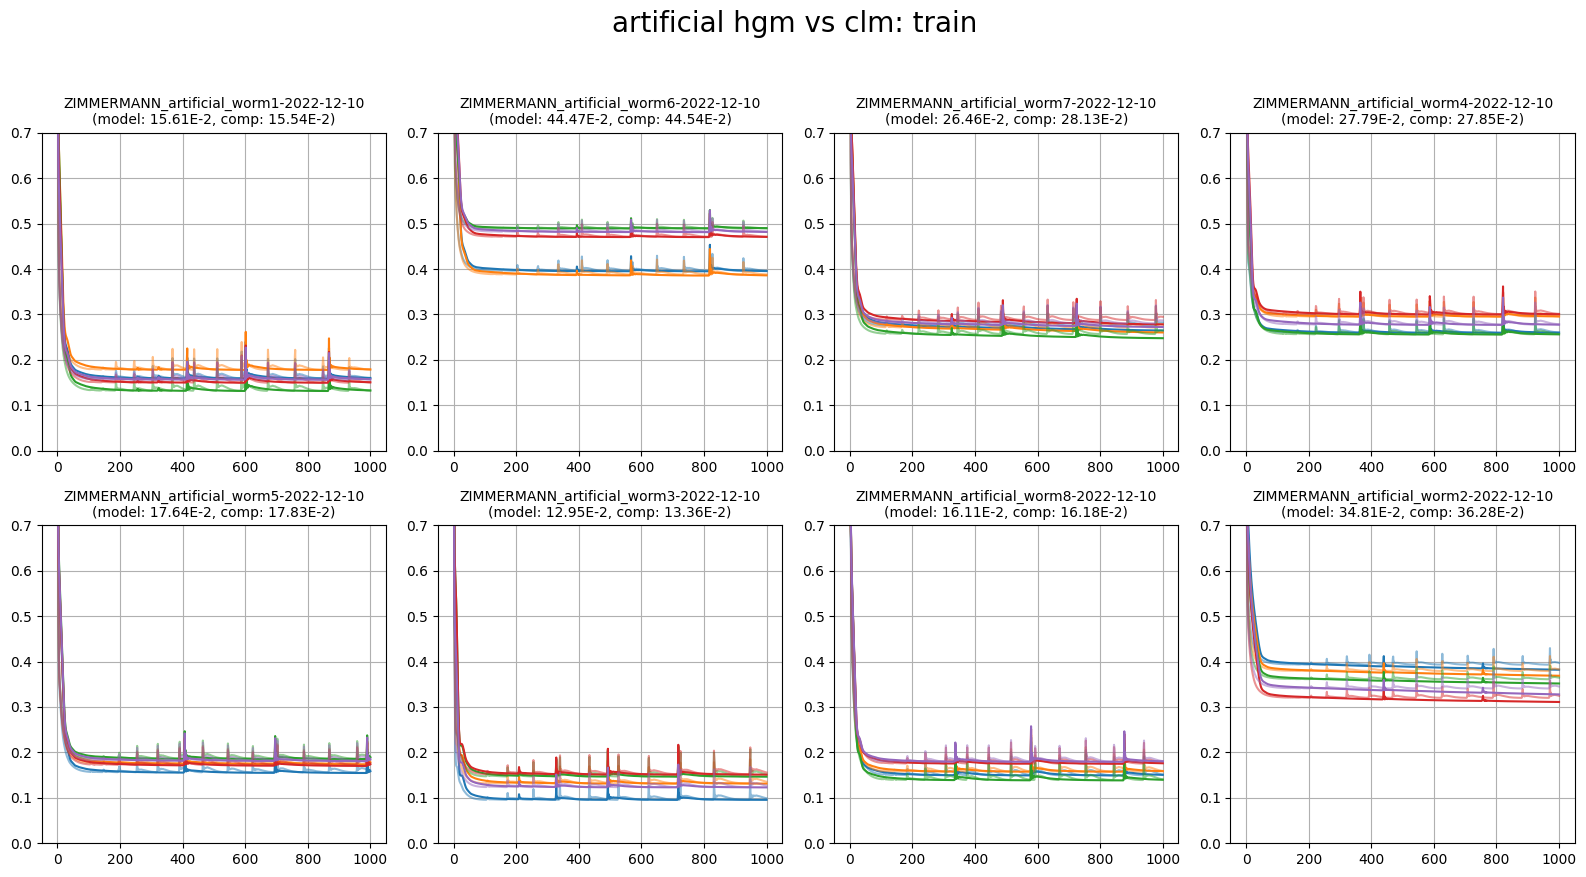

In [21]:
plot_utils.plot_losses(filenames_art, hgm_models_losses_tr_art, clm_models_losses_tr_art, 'artificial hgm vs clm: train', None,  (0.0, 0.7))

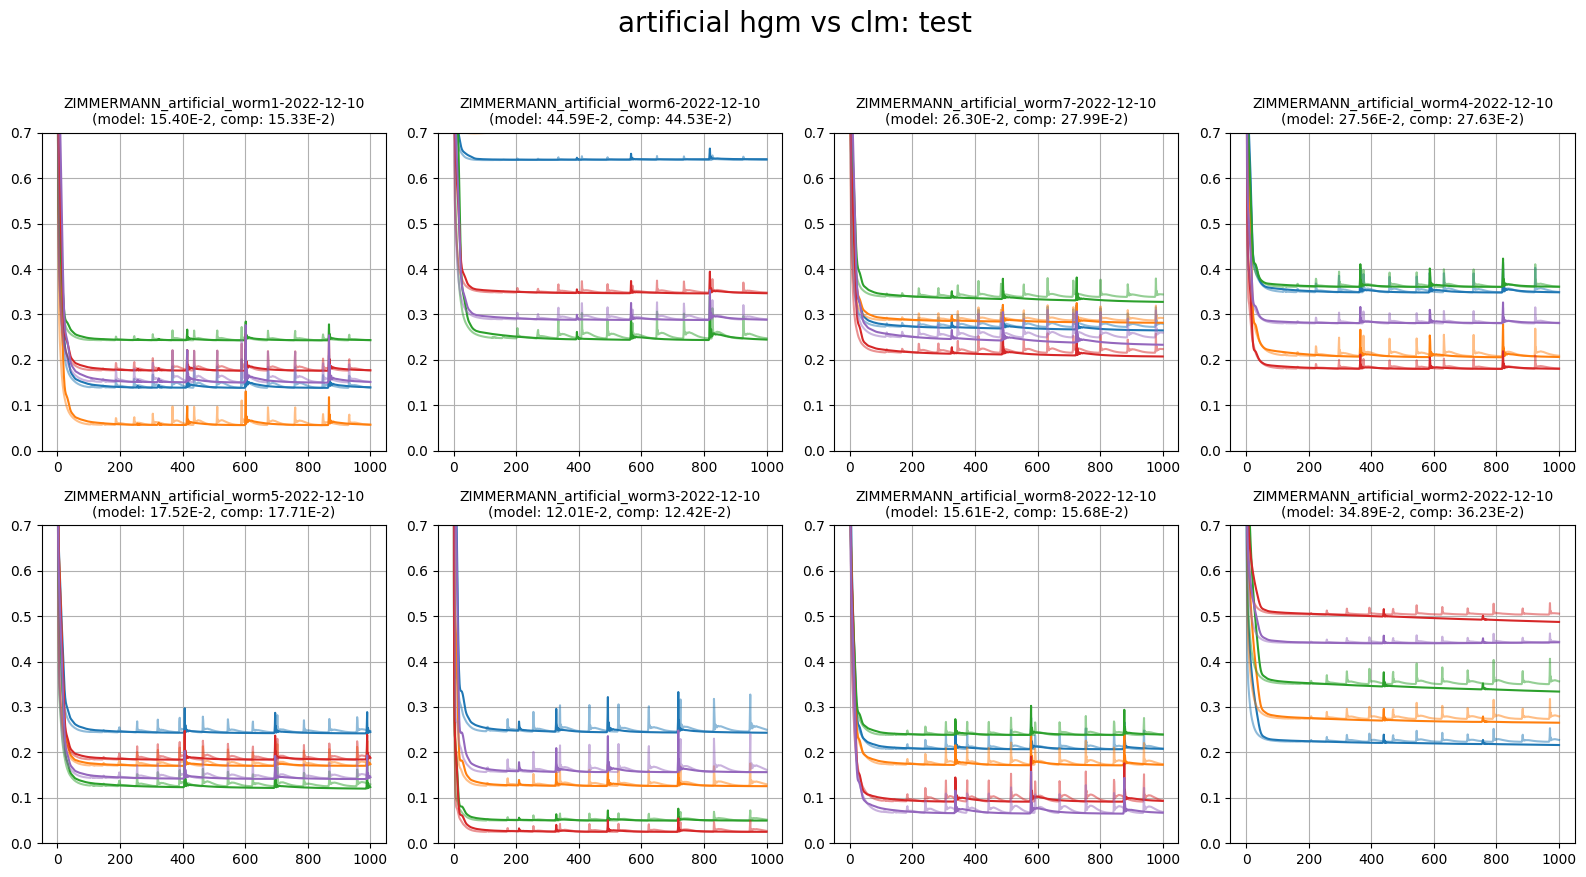

In [22]:
plot_utils.plot_losses(filenames_art, hgm_models_losses_art, clm_models_losses_art, 'artificial hgm vs clm: test', None,  (0.0, 0.7))

In [23]:
# assemble art

neurons_labels_art = [traces_art[i].columns for i in range(len(filenames_art))]

# unique_labels_art = sorted(list(set([l for label in neurons_labels_art for l in label])))
# unique_labels_filtered_art = [label for label in unique_labels_art if label != '' and label[-1] != '_']

neuron_scores_art = dict()
clm_models_avg_scores_art = [np.mean(scores, axis=0) for scores in clm_models_scores_art]
hgm_models_avg_scores_art = [np.mean(scores, axis=0) for scores in hgm_models_scores_art]
for label_list, score_clm_list, score_hgm_list in zip(neurons_labels_art, clm_models_avg_scores_art, hgm_models_avg_scores_art):
	for i in range(len(label_list)):
		label = label_list[i]
		if label == '' or label[-1] == '_': continue

		score_clm_new, score_hgm_new = np.array(score_clm_list[i]), np.array(score_hgm_list[i])
		if len(score_hgm_new.shape) == 0:
			score_clm_new = score_clm_new.reshape(1, 1)
			score_hgm_new = score_hgm_new.reshape(1, 1)
		if label not in neuron_scores_art.keys():
			neuron_scores_art[label] = (score_clm_new, score_hgm_new)
		else:
			score_clm_prev, score_hgm_prev = neuron_scores_art[label]
			neuron_scores_art[label] = (np.vstack([score_clm_prev, score_clm_new]), np.vstack([score_hgm_prev, score_hgm_new]))

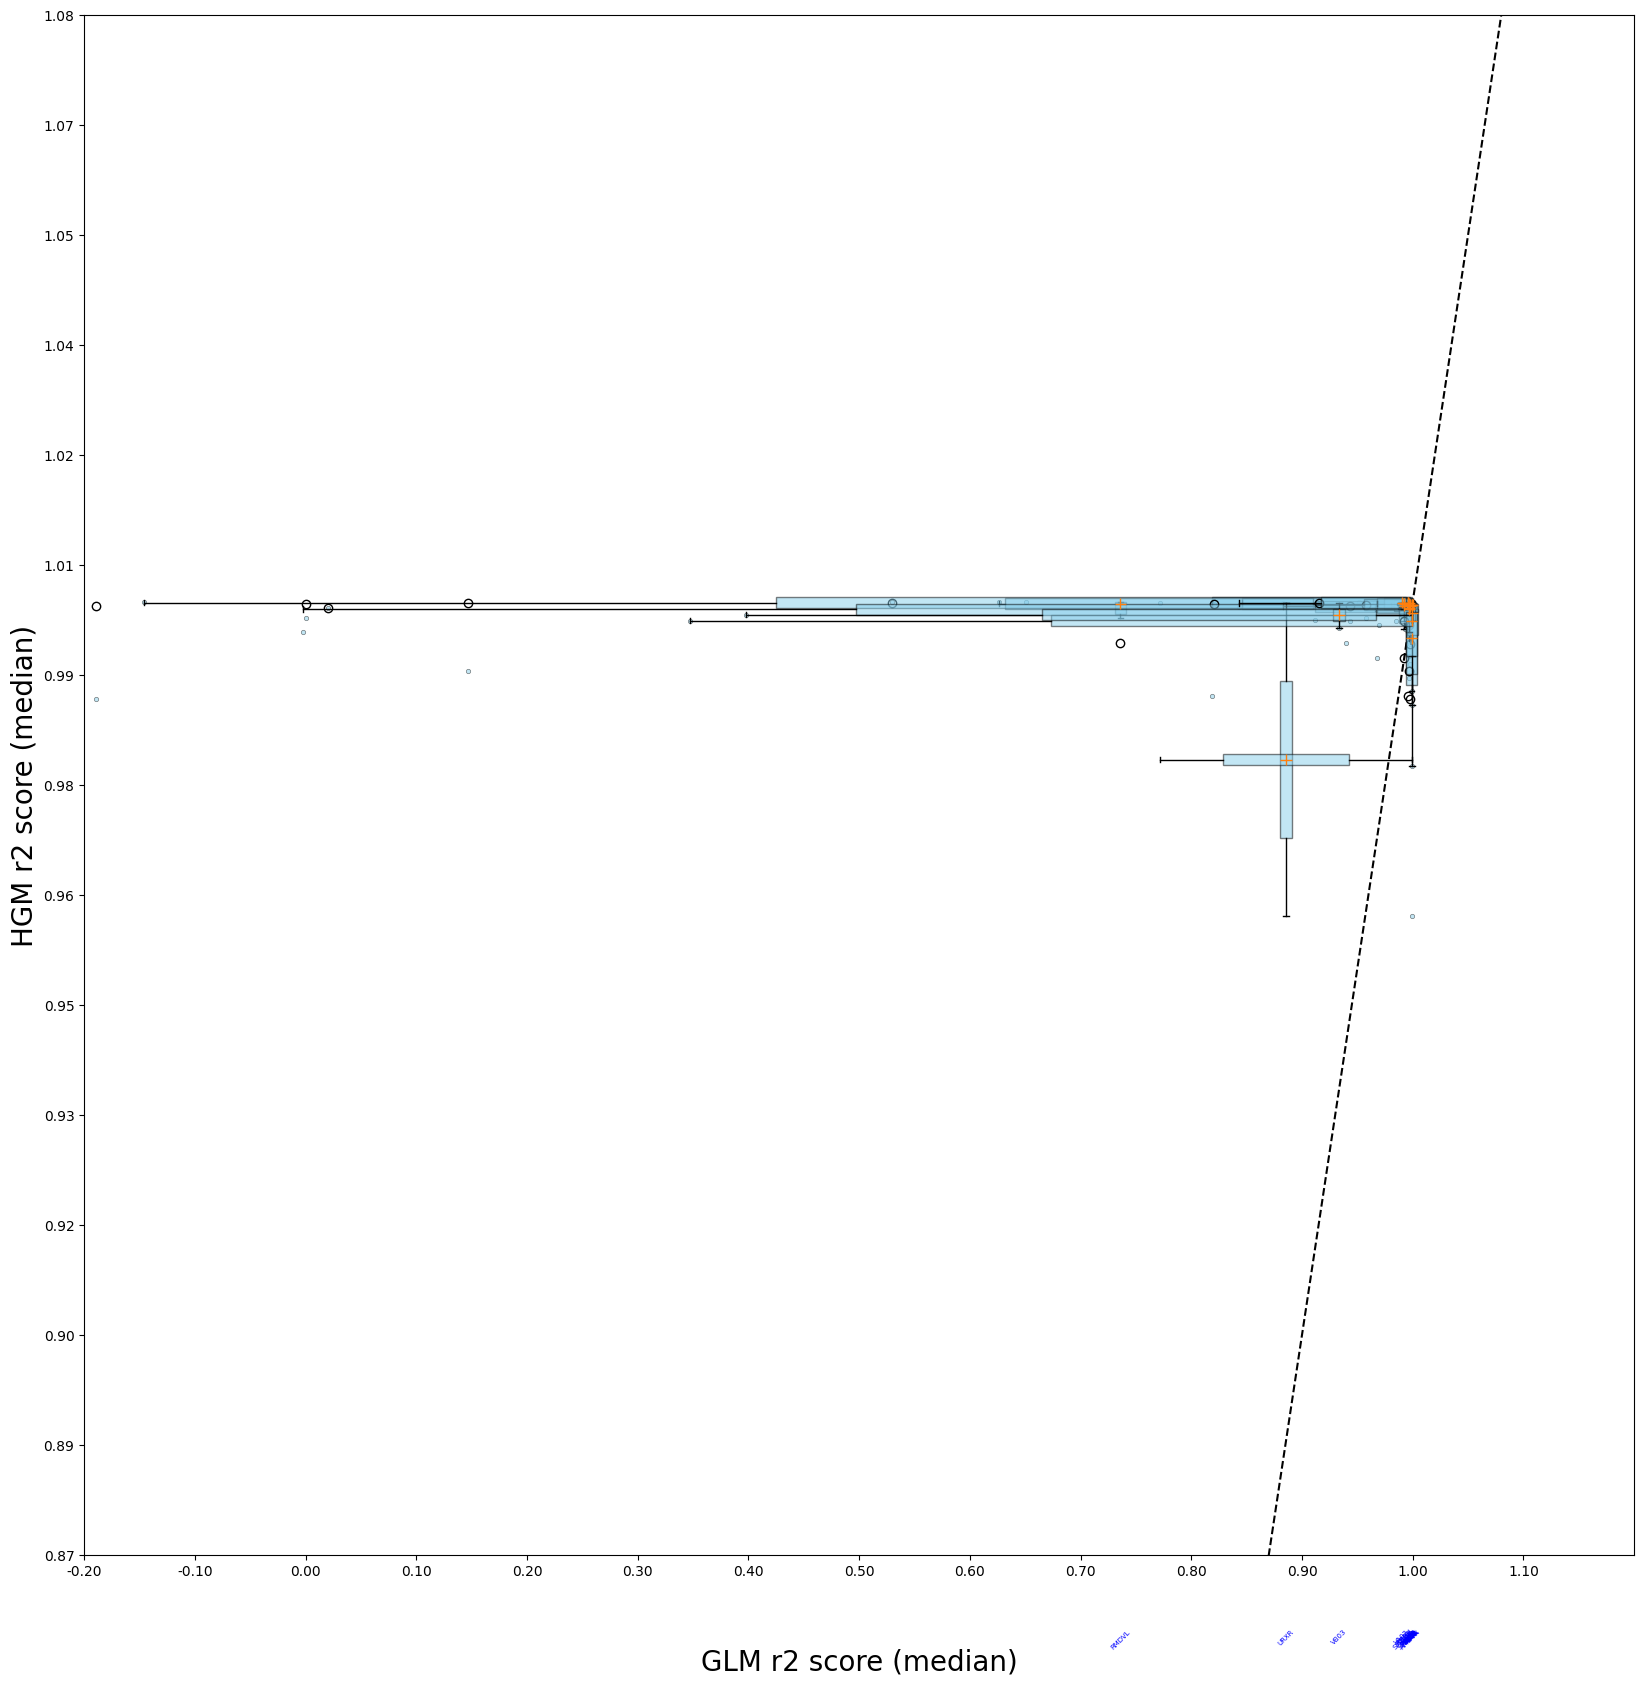

In [27]:
# plot art

plot_utils.plot_performance_plot(neuron_scores_art, None, (0, 1, 0.9, 1.05), save=True)

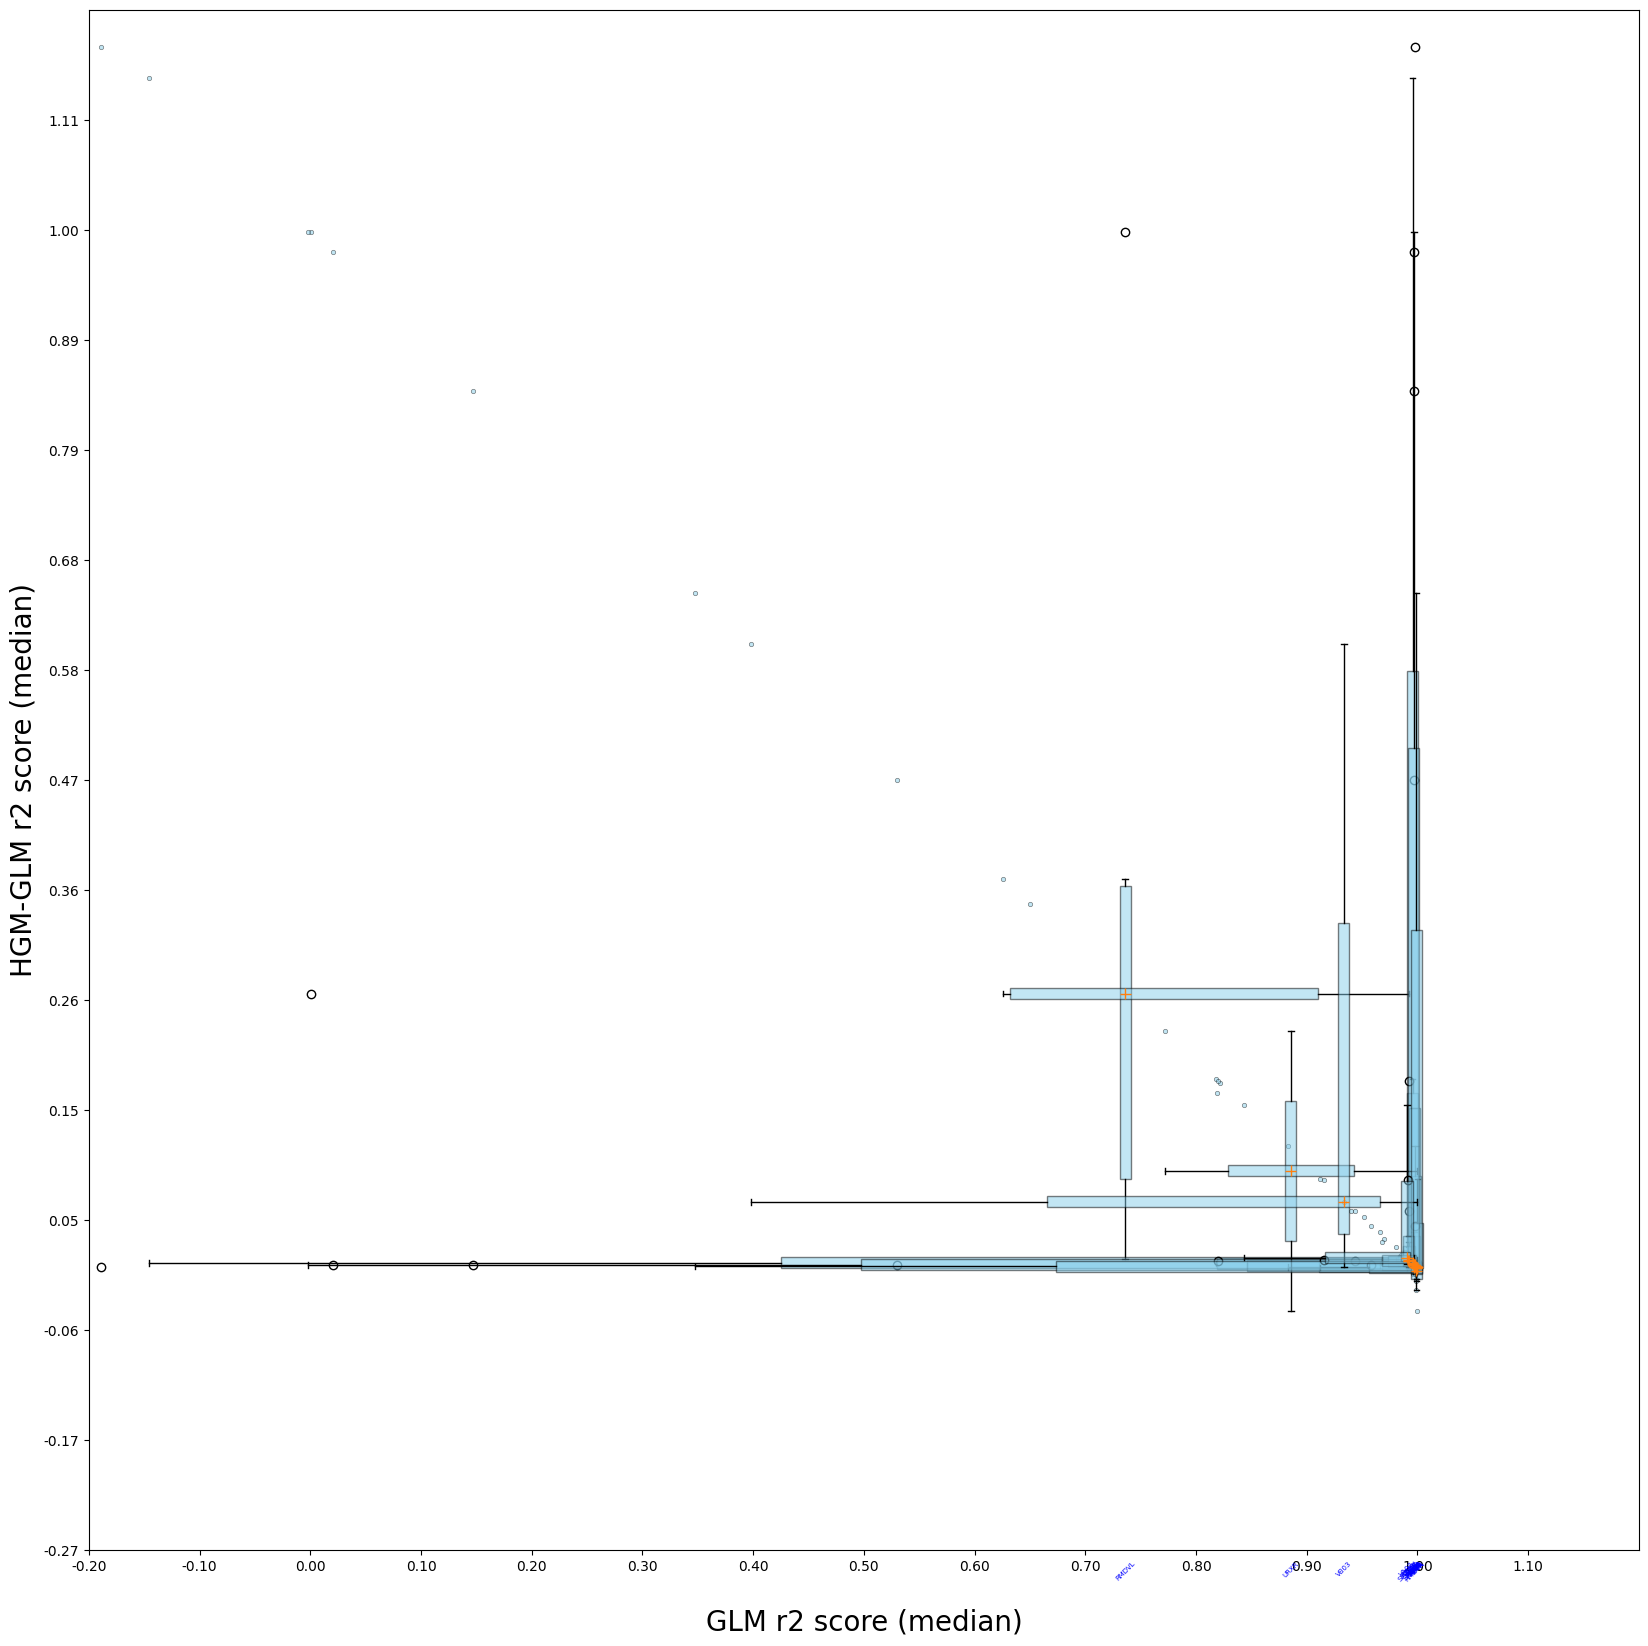

In [33]:
# plot art

plot_utils.plot_improvement_plot(neuron_scores_art, None, (0, 1, -0.06, 1), save=True)

# ARTIFICIAL DATA END

In [ ]:
if True: raise Exception

# GCAMP

### CLM

In [34]:
selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

clm_models_params = list()
clm_models_scores = list()
clm_models_losses = list()
clm_models_losses_tr = list()
mse_clm_models_losses = list()
mse_clm_models_losses_tr = list()
__clm_models_grads = list()

for i in range(len(filenames)):
	print(f'{i+1}/{len(filenames)}: {filenames[i]}  ', end='')

	splits = list(StratifiedKFold(n_splits=5).split(np.zeros(traces[i].values.shape[0]), discrete_states[i]['REV'].values))

	(params_per_split,
	 neuron_scores_per_split,
	 losses_per_split, losses_tr_per_split,
	 mse_losses_per_split, mse_losses_tr_per_split,
	 __grads_per_split) = train_joint_model(clm, splits,
											jnp.array(traces[i].values),
											jnp.array(eigenworms[i].values),
											jnp.array(discrete_states[i][selection].values))

	clm_models_params.append(params_per_split)
	clm_models_scores.append(neuron_scores_per_split)
	clm_models_losses.append(losses_per_split)
	clm_models_losses_tr.append(losses_tr_per_split)
	mse_clm_models_losses.append(mse_losses_per_split)
	mse_clm_models_losses_tr.append(mse_losses_tr_per_split)
	__clm_models_grads.append(__grads_per_split)

1/34: ZIM2165_Gcamp7b_worm7-2022-12-10_no_image_data  2/34: ZIM2165_Gcamp7b_worm1-2022-12-10_no_image_data  3/34: ZIM2165_Gcamp7b_worm2-2022-11-30_no_image_data  4/34: ZIM2165_Gcamp7b_worm2-2022-12-10_no_image_data  5/34: ZIM2165_Gcamp7b_worm5-2022_11_28_no_image_data  6/34: 2024-01-11_16-42_wt_FM_worm06-2024-01-11_no_image_data  7/34: ZIM2165_Gcamp7b_worm1-2022-11-30_no_image_data  8/34: 2024-01-30_16-32_wt_worm1-2024-01-30_no_image_data  9/34: ZIM2165_Gcamp7b_worm6-2022_11_28_no_image_data  10/34: 2022-11-23_worm10_no_image_data  11/34: 2022-11-23_worm12_no_image_data  12/34: ZIM2165_Gcamp7b_worm3-2022-12-10_no_image_data  13/34: 2022-11-23_worm11_no_image_data  14/34: 2023-11-30_14-31_wt_worm5_FM-2023-11-30_no_image_data  15/34: ZIM2165_Gcamp7b_worm8-2022-12-10_no_image_data  16/34: 2024-01-30_17-00_wt_worm2-2024-01-30_no_image_data  17/34: ZIM2165_Gcamp7b_worm3-2022-12-05_no_image_data  18/34: ZIM2165_Gcamp7b_worm4-2022_11_28_no_image_data  19/34: 2023-12-19_18-27_wt_FM_worm5again2

### HGM

In [35]:
selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

hgm_models_params = list()
hgm_models_scores = list()
hgm_models_losses = list()
hgm_models_losses_tr = list()
mse_hgm_models_losses = list()
mse_hgm_models_losses_tr = list()
__hgm_models_grads = list()

for i in range(len(filenames)):
	print(f'{i+1}/{len(filenames)}: {filenames[i]}  ', end='')

	splits = list(StratifiedKFold(n_splits=5).split(np.zeros(traces[i].shape[0]), discrete_states[i]['REV'].values))

	(params_per_split,
	 neuron_scores_per_split,
	 losses_per_split, losses_tr_per_split,
	 mse_losses_per_split, mse_losses_tr_per_split,
	 __grads_per_split) = train_joint_model(hgm, splits,
											jnp.array(traces[i].values),
											jnp.array(eigenworms[i].values),
											jnp.array(discrete_states[i][selection].values))

	hgm_models_params.append(params_per_split)
	hgm_models_scores.append(neuron_scores_per_split)
	hgm_models_losses.append(losses_per_split)
	hgm_models_losses_tr.append(losses_tr_per_split)
	mse_hgm_models_losses.append(mse_losses_per_split)
	mse_hgm_models_losses_tr.append(mse_losses_tr_per_split)
	__hgm_models_grads.append(__grads_per_split)

1/34: ZIM2165_Gcamp7b_worm7-2022-12-10_no_image_data  2/34: ZIM2165_Gcamp7b_worm1-2022-12-10_no_image_data  3/34: ZIM2165_Gcamp7b_worm2-2022-11-30_no_image_data  4/34: ZIM2165_Gcamp7b_worm2-2022-12-10_no_image_data  5/34: ZIM2165_Gcamp7b_worm5-2022_11_28_no_image_data  6/34: 2024-01-11_16-42_wt_FM_worm06-2024-01-11_no_image_data  7/34: ZIM2165_Gcamp7b_worm1-2022-11-30_no_image_data  8/34: 2024-01-30_16-32_wt_worm1-2024-01-30_no_image_data  9/34: ZIM2165_Gcamp7b_worm6-2022_11_28_no_image_data  10/34: 2022-11-23_worm10_no_image_data  11/34: 2022-11-23_worm12_no_image_data  12/34: ZIM2165_Gcamp7b_worm3-2022-12-10_no_image_data  13/34: 2022-11-23_worm11_no_image_data  14/34: 2023-11-30_14-31_wt_worm5_FM-2023-11-30_no_image_data  15/34: ZIM2165_Gcamp7b_worm8-2022-12-10_no_image_data  16/34: 2024-01-30_17-00_wt_worm2-2024-01-30_no_image_data  17/34: ZIM2165_Gcamp7b_worm3-2022-12-05_no_image_data  18/34: ZIM2165_Gcamp7b_worm4-2022_11_28_no_image_data  19/34: 2023-12-19_18-27_wt_FM_worm5again2

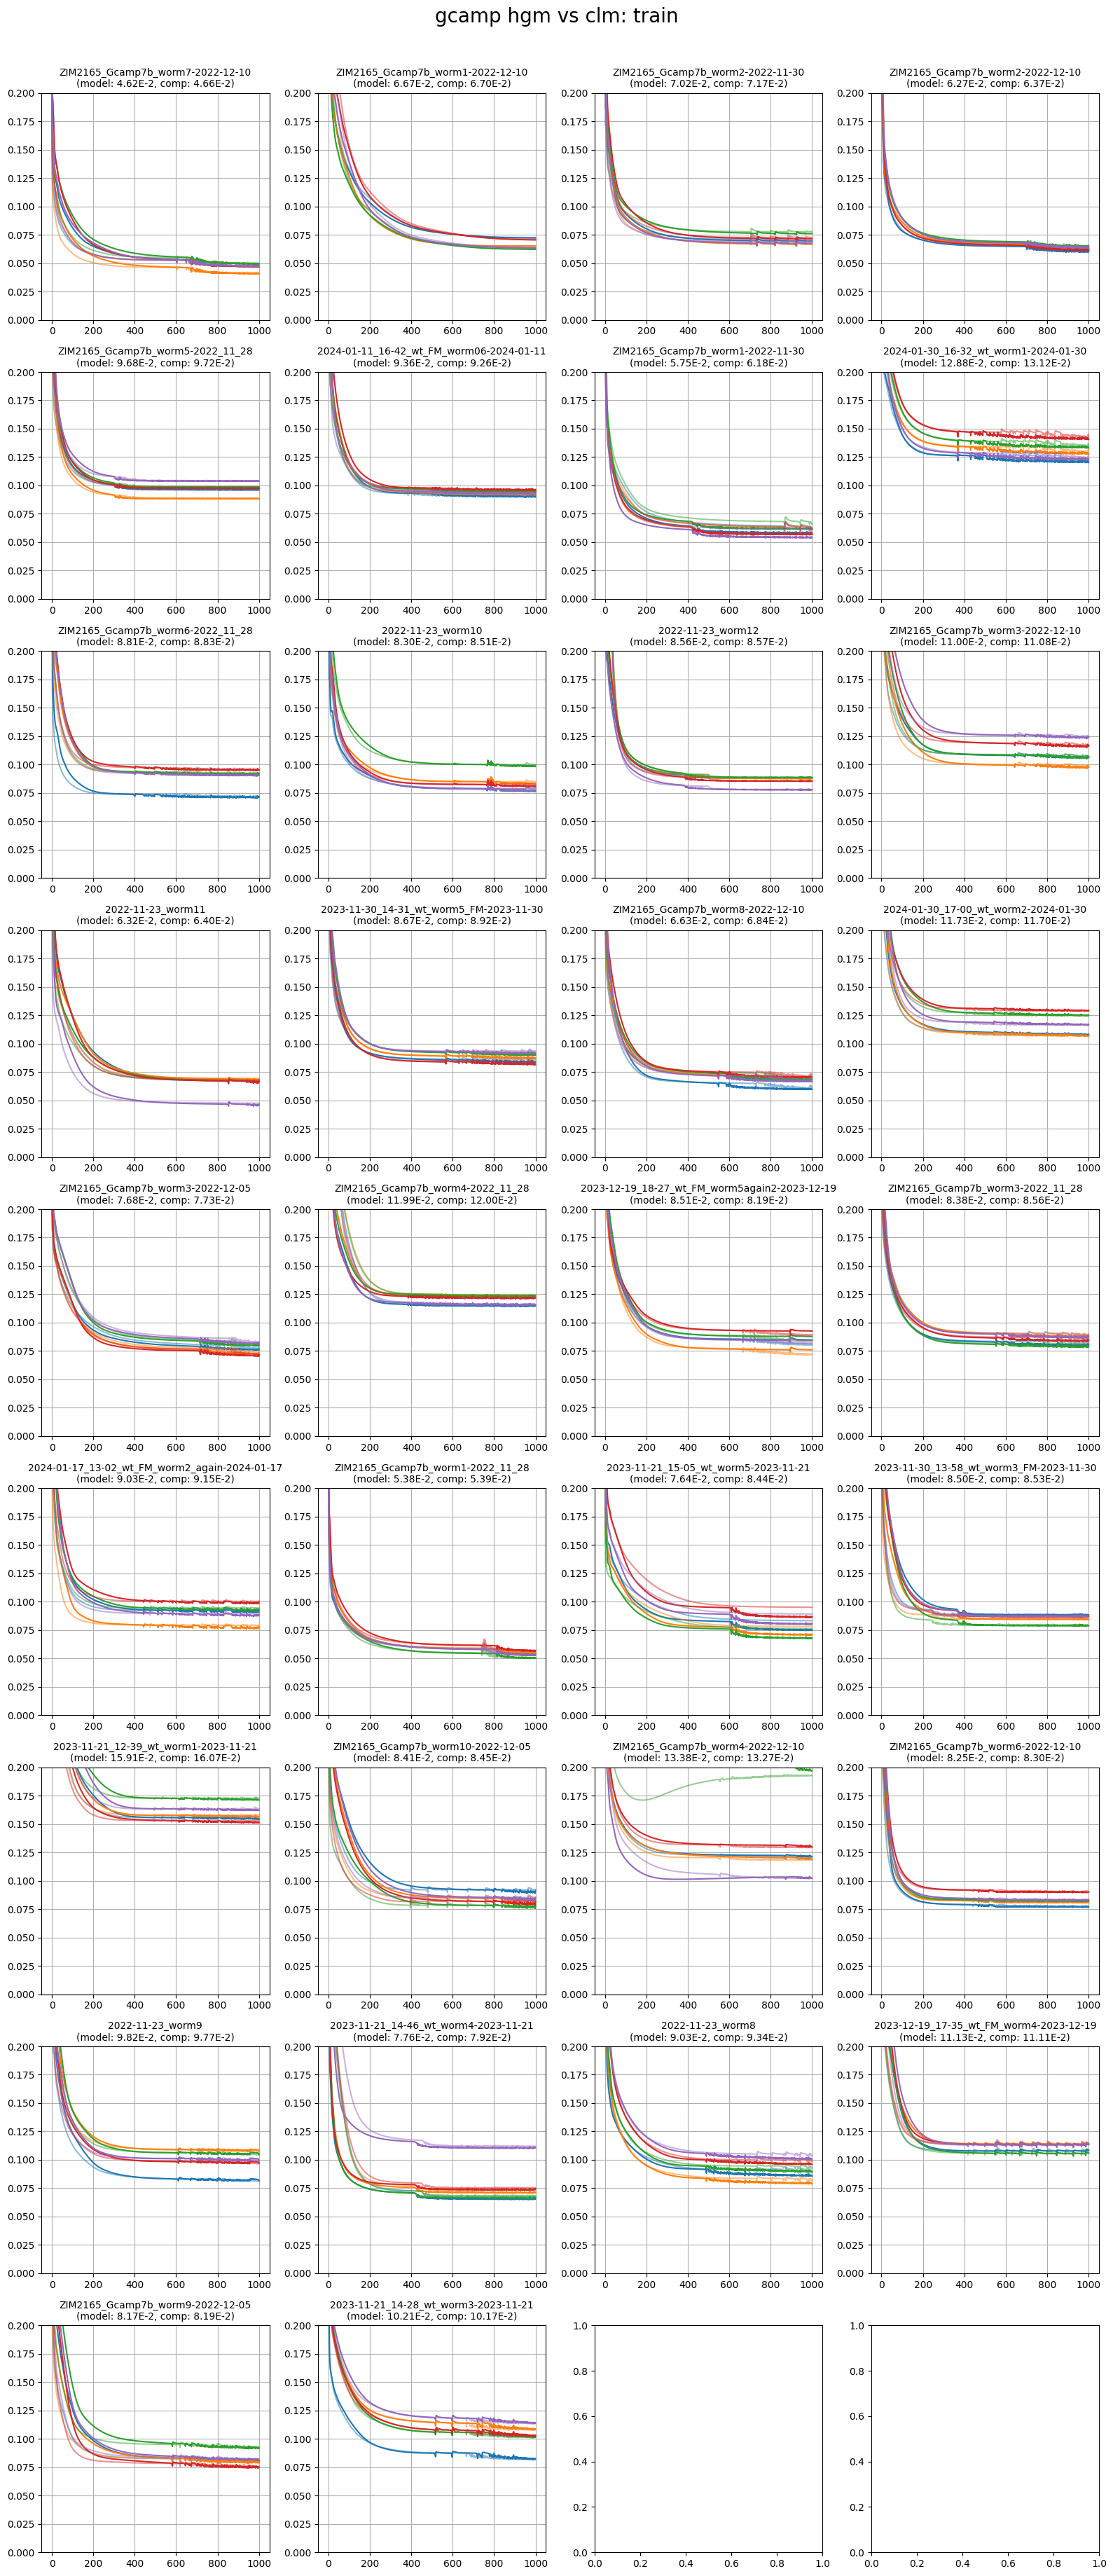

In [38]:
plot_utils.plot_losses(filenames, hgm_models_losses_tr, clm_models_losses_tr, 'gcamp hgm vs clm: train', None, (0.0, 0.02))

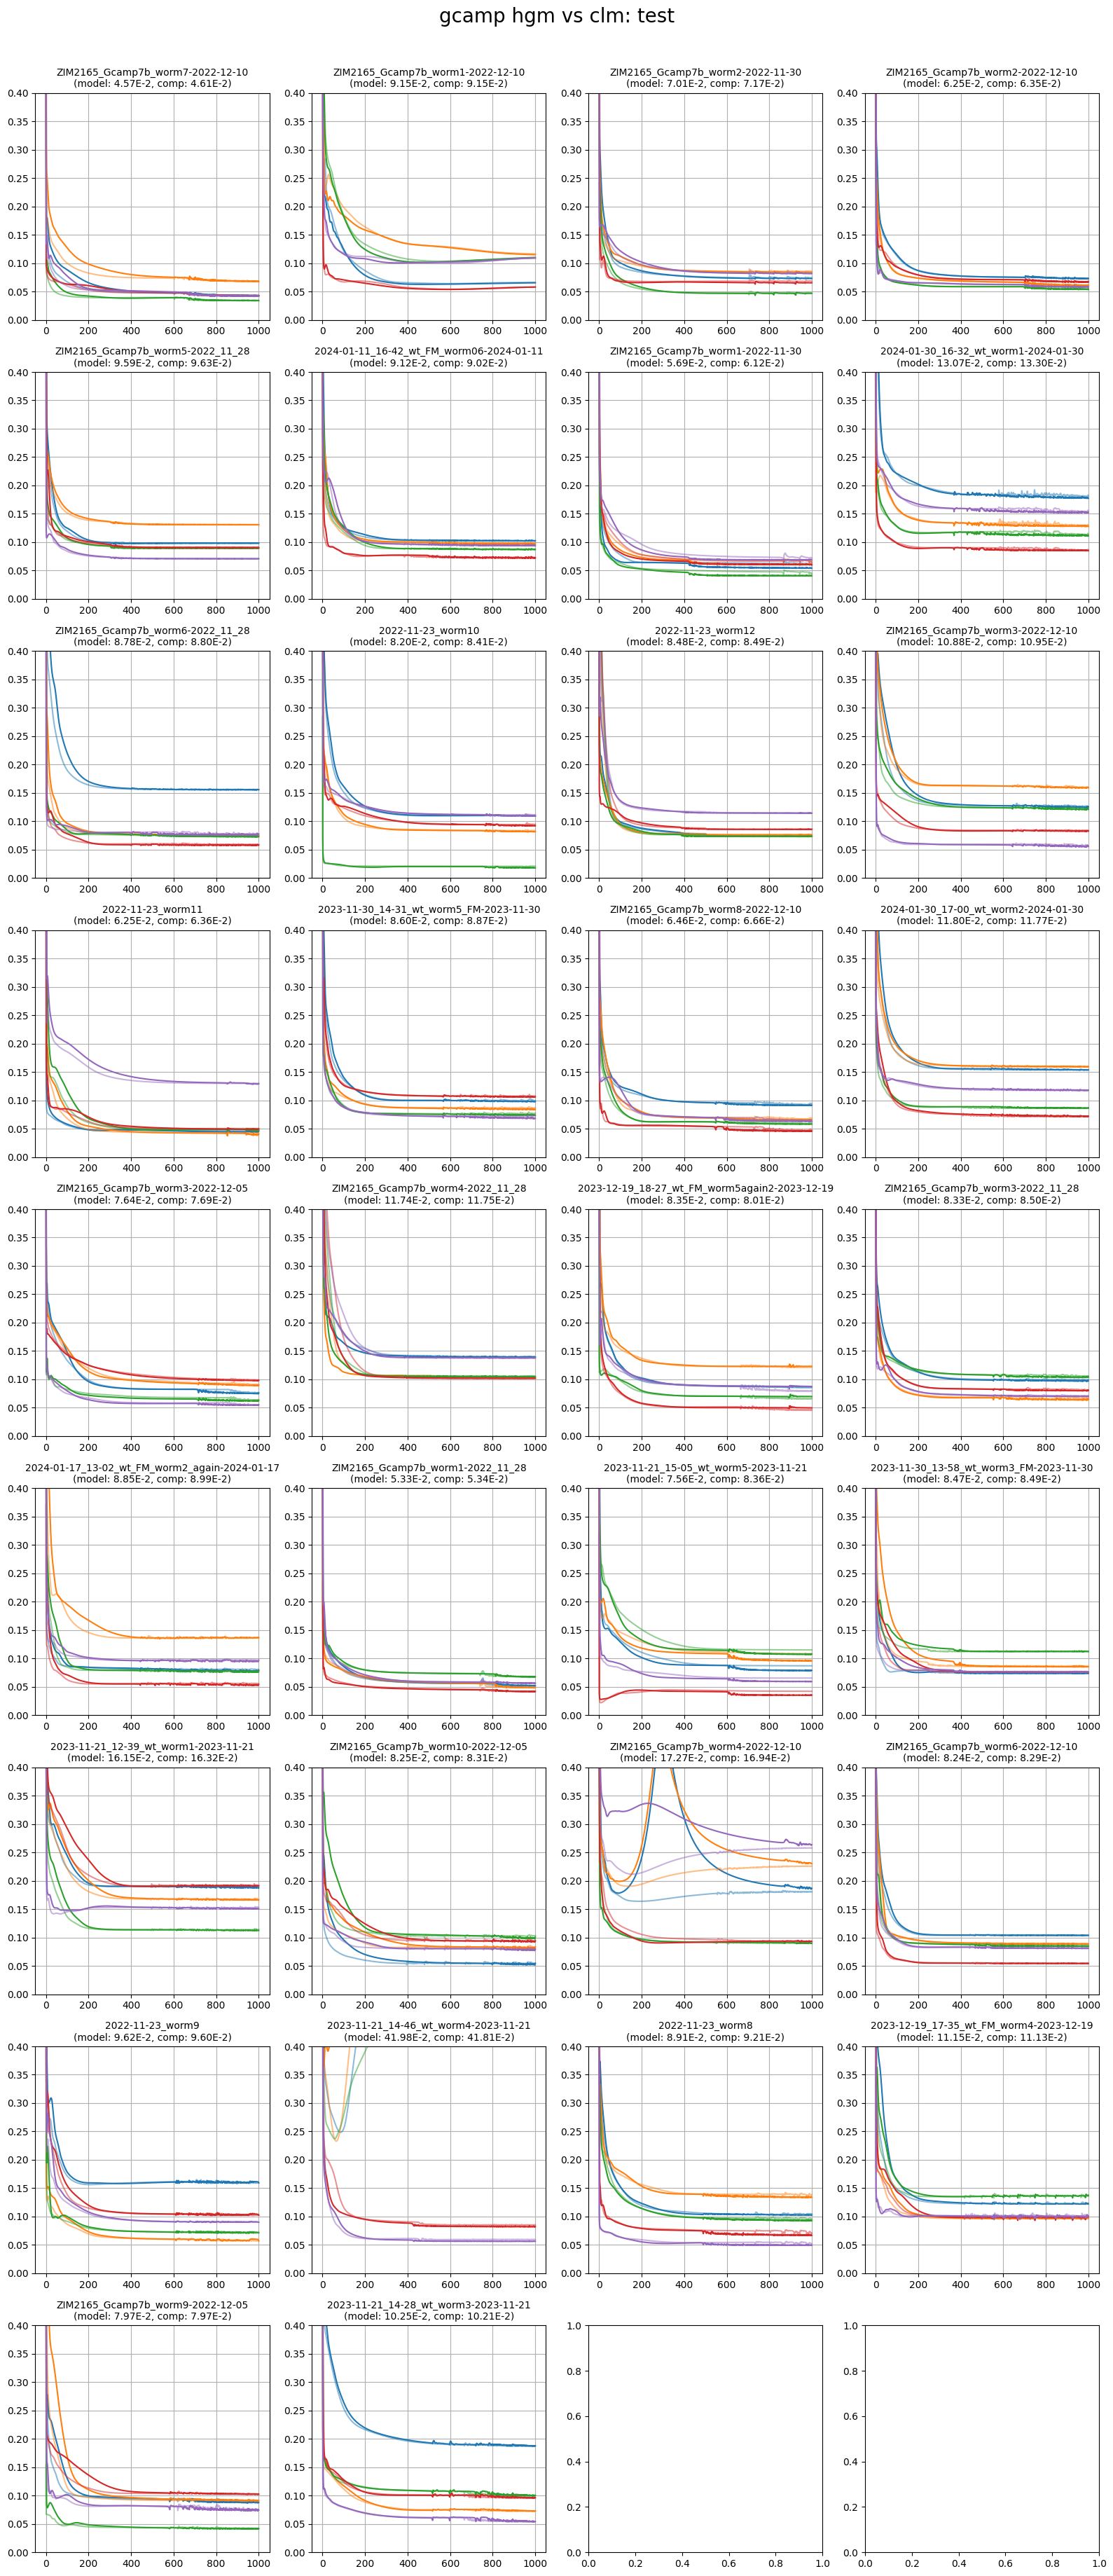

In [42]:
plot_utils.plot_losses(filenames, hgm_models_losses, clm_models_losses, 'gcamp hgm vs clm: test', None, (0.0, 0.4))

### plots

### __loss gradient per weights over time

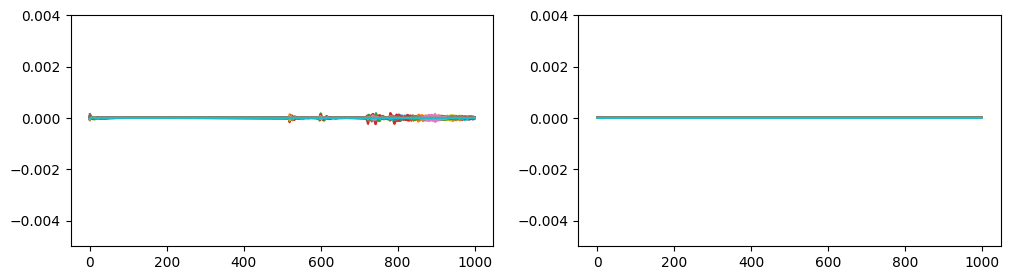

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for ax in axes:
    ax.set_ylim(-0.005, 0.004)

for i in range(1):
	gradsW = np.array([val['W'] for val in __clm_models_grads[-1][i]])

	gradsW1 = np.array([val['W1'] for val in __hgm_models_grads[-1][i]])
	gradsW2 = np.array([val['W2'] for val in __hgm_models_grads[-1][i]])


	axes[0].plot(np.mean(gradsW1, axis=1))

	# axes[1].plot(np.mean(gradsW1, axis=1))
	axes[1].plot(np.mean(gradsW2, axis=1))

# GFP

### CLM

In [44]:
selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

clm_models_params_gfp = list()
clm_models_scores_gfp = list()
clm_models_losses_gfp = list()
clm_models_losses_tr_gfp = list()
mse_clm_models_losses_gfp = list()
mse_clm_models_losses_tr_gfp = list()
__clm_models_grads_gfp = list()

for i in range(len(filenames_gfp)):
	print(f'{i+1}/{len(filenames_gfp)}: {filenames_gfp[i]}  ', end='')

	splits = list(StratifiedKFold(n_splits=5).split(np.zeros(traces_gfp[i].shape[0]), discrete_states_gfp[i]['REV'].values))

	(params_per_split,
	 neuron_scores_per_split,
	 losses_per_split, losses_tr_per_split,
	 mse_losses_per_split, mse_losses_tr_per_split,
	 __grads_per_split) = train_joint_model(clm, splits,
											jnp.array(traces_gfp[i].values),
											jnp.array(eigenworms_gfp[i].values),
											jnp.array(discrete_states_gfp[i][selection].values))

	clm_models_params_gfp.append(params_per_split)
	clm_models_scores_gfp.append(neuron_scores_per_split)
	clm_models_losses_gfp.append(losses_per_split)
	clm_models_losses_tr_gfp.append(losses_tr_per_split)
	mse_clm_models_losses_gfp.append(mse_losses_per_split)
	mse_clm_models_losses_tr_gfp.append(mse_losses_tr_per_split)
	__clm_models_grads_gfp.append(__grads_per_split)

1/8: ZIM2319_GFP_worm1-2022-12-10_no_image_data  2/8: ZIM2319_GFP_worm6-2022-12-10_no_image_data  3/8: ZIM2319_GFP_worm7-2022-12-10_no_image_data  4/8: ZIM2319_GFP_worm4-2022-12-10_no_image_data  5/8: ZIM2319_GFP_worm5-2022-12-10_no_image_data  6/8: ZIM2319_GFP_worm3-2022-12-10_no_image_data  7/8: ZIM2319_GFP_worm8-2022-12-10_no_image_data  8/8: ZIM2319_GFP_worm2-2022-12-10_no_image_data  

### HGM

In [45]:
selection = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

hgm_models_params_gfp = list()
hgm_models_scores_gfp = list()
hgm_models_losses_gfp = list()
hgm_models_losses_tr_gfp = list()
mse_hgm_models_losses_gfp = list()
mse_hgm_models_losses_tr_gfp = list()
__hgm_models_grads_gfp = list()

for i in range(len(filenames_gfp)):
	print(f'{i+1}/{len(filenames_gfp)}: {filenames_gfp[i]}  ', end='')

	splits = list(StratifiedKFold(n_splits=5).split(np.zeros(traces_gfp[i].shape[0]), discrete_states_gfp[i]['REV'].values))

	(params_per_split,
	 neuron_scores_per_split,
	 losses_per_split, losses_tr_per_split,
	 mse_losses_per_split, mse_losses_tr_per_split,
	 __grads_per_split) = train_joint_model(hgm, splits,
											jnp.array(traces_gfp[i].values),
											jnp.array(eigenworms_gfp[i].values),
											jnp.array(discrete_states_gfp[i][selection].values))

	hgm_models_params_gfp.append(params_per_split)
	hgm_models_scores_gfp.append(neuron_scores_per_split)
	hgm_models_losses_gfp.append(losses_per_split)
	hgm_models_losses_tr_gfp.append(losses_tr_per_split)
	mse_hgm_models_losses_gfp.append(mse_losses_per_split)
	mse_hgm_models_losses_tr_gfp.append(mse_losses_tr_per_split)
	__hgm_models_grads_gfp.append(__grads_per_split)

1/8: ZIM2319_GFP_worm1-2022-12-10_no_image_data  2/8: ZIM2319_GFP_worm6-2022-12-10_no_image_data  3/8: ZIM2319_GFP_worm7-2022-12-10_no_image_data  4/8: ZIM2319_GFP_worm4-2022-12-10_no_image_data  5/8: ZIM2319_GFP_worm5-2022-12-10_no_image_data  6/8: ZIM2319_GFP_worm3-2022-12-10_no_image_data  7/8: ZIM2319_GFP_worm8-2022-12-10_no_image_data  8/8: ZIM2319_GFP_worm2-2022-12-10_no_image_data  

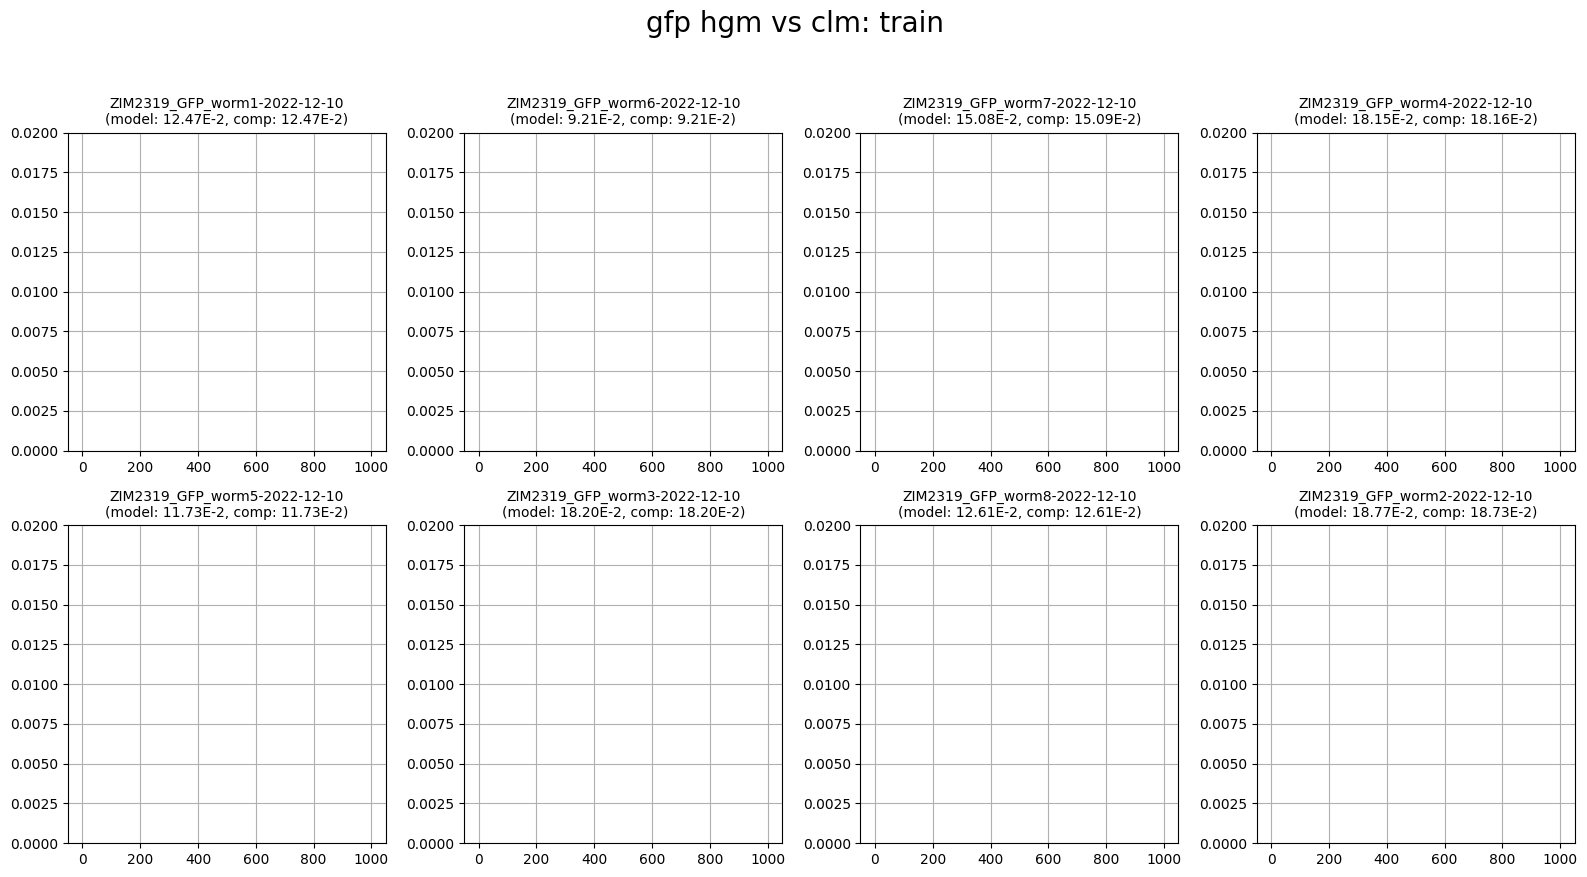

In [46]:
plot_utils.plot_losses(filenames_gfp, hgm_models_losses_tr_gfp, clm_models_losses_tr_gfp, 'gfp hgm vs clm: train', None,  None)

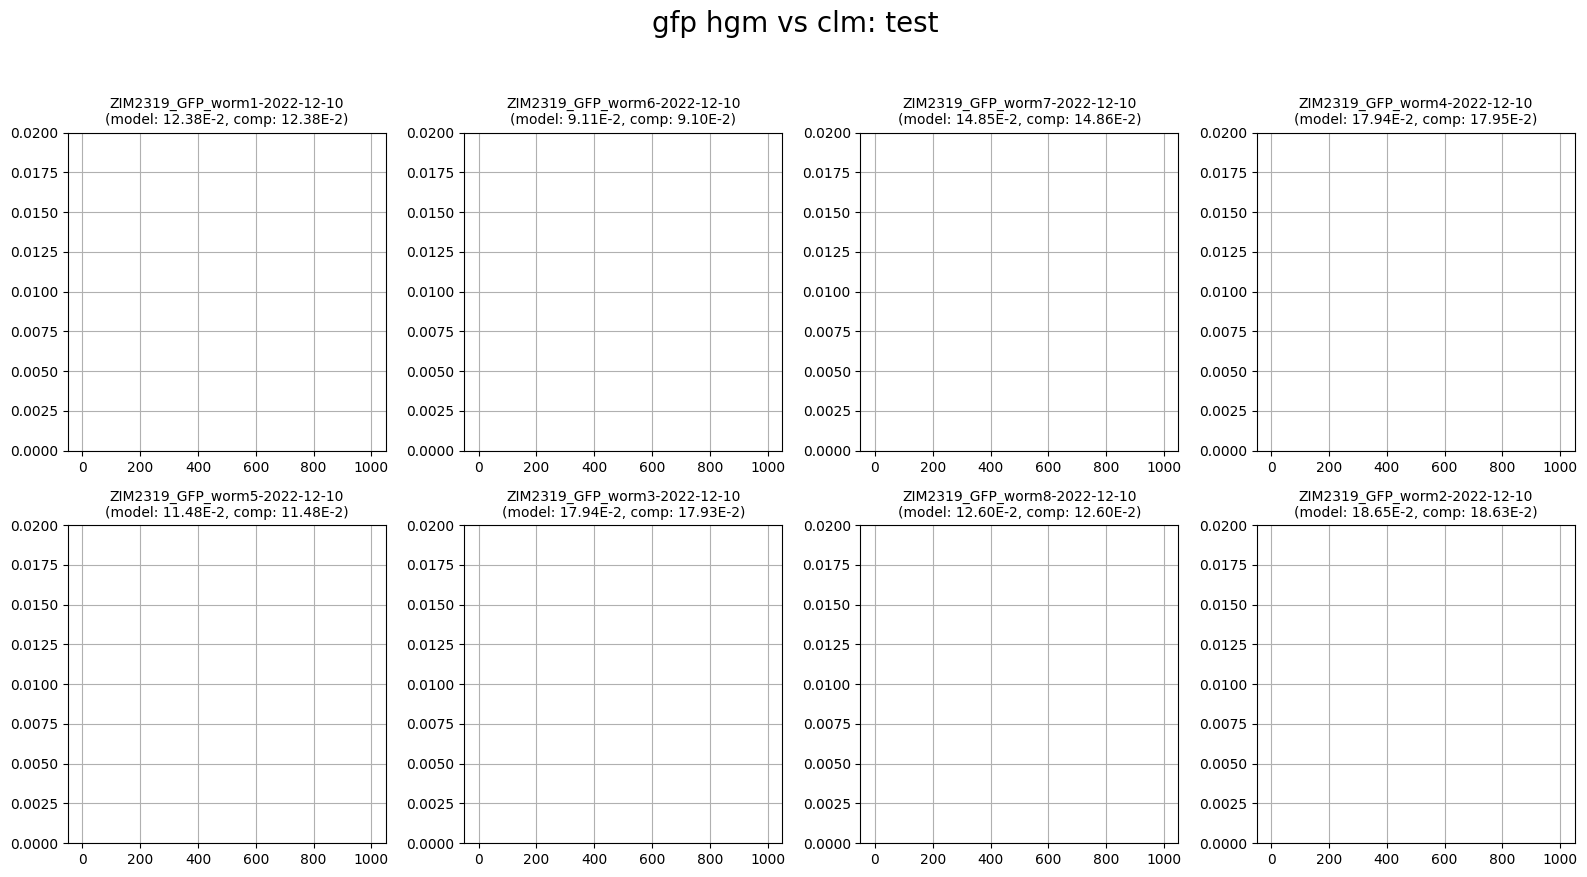

In [47]:
plot_utils.plot_losses(filenames_gfp, hgm_models_losses_gfp, clm_models_losses_gfp, 'gfp hgm vs clm: test', None,  None)

# assemble

In [48]:
neurons_labels = [traces[i].columns for i in range(len(filenames))]

# unique_labels = sorted(list(set([l for label in neurons_labels for l in label])))
# unique_labels_filtered = [label for label in unique_labels if label != '' and label[-1] != '_']

neuron_scores = dict()
clm_models_avg_scores = [np.mean(scores, axis=0) for scores in clm_models_scores]
hgm_models_avg_scores = [np.mean(scores, axis=0) for scores in hgm_models_scores]
for label_list, score_clm_list, score_hgm_list in zip(neurons_labels, clm_models_avg_scores, hgm_models_avg_scores):
	for i in range(len(label_list)):
		label = label_list[i]
		if label != '' and label[-1] != '_':
			score_clm_new, score_hgm_new = np.array(score_clm_list[i]), np.array(score_hgm_list[i])
			if len(score_hgm_new.shape) == 0:
				score_clm_new = score_clm_new.reshape(1, 1)
				score_hgm_new = score_hgm_new.reshape(1, 1)
			if label not in neuron_scores.keys():
				neuron_scores[label] = (score_clm_new, score_hgm_new)
			else:
				score_clm_prev, score_hgm_prev = neuron_scores[label]
				neuron_scores[label] = (np.vstack([score_clm_prev, score_clm_new]), np.vstack([score_hgm_prev, score_hgm_new]))

In [49]:
neurons_labels_gfp = [traces_gfp[i].columns for i in range(len(filenames_gfp))]

# unique_labels_gfp = sorted(list(set([l for label in neurons_labels_gfp for l in label])))
# unique_labels_filtered_gfp = [label for label in unique_labels_gfp if label != '' and label[-1] != '_']

neuron_scores_gfp = dict()
clm_models_avg_scores_gfp = [np.mean(scores, axis=0) for scores in clm_models_scores_gfp]
hgm_models_avg_scores_gfp = [np.mean(scores, axis=0) for scores in hgm_models_scores_gfp]
for label_list, score_clm_list, score_hgm_list in zip(neurons_labels_gfp, clm_models_avg_scores_gfp, hgm_models_avg_scores_gfp):
	for i in range(len(label_list)):
		label = label_list[i]
		if label != '' and label[-1] != '_':
			score_clm_new, score_hgm_new = np.array(score_clm_list[i]), np.array(score_hgm_list[i])
			if len(score_hgm_new.shape) == 0:
				score_clm_new = score_clm_new.reshape(1, 1)
				score_hgm_new = score_hgm_new.reshape(1, 1)
			if label not in neuron_scores_gfp.keys():
				neuron_scores_gfp[label] = (score_clm_new, score_hgm_new)
			else:
				score_clm_prev, score_hgm_prev = neuron_scores_gfp[label]
				neuron_scores_gfp[label] = (np.vstack([score_clm_prev, score_clm_new]), np.vstack([score_hgm_prev, score_hgm_new]))

# Plot

In [1]:
plot_utils.plot_performance_plot(neuron_scores, neuron_scores_gfp, (-0.5, 0.3, -1.1, 0.4), save=True)

NameError: name 'plot_utils' is not defined

In [ ]:
plot_utils.plot_improvement_plot(neuron_scores, neuron_scores_gfp, (-1, 0.5, -0.3, 1), save=True)